# Séance 3 — Nettoyage et qualité des données

**Durée pratique : 3 h 30** &nbsp;·&nbsp; Ateliers 3.1 à 3.4

## Ce que vous saurez faire à la fin

- classer les valeurs manquantes et choisir un traitement adapté à chaque colonne ;
- détecter les valeurs aberrantes par écart interquartile et par score z, et arbitrer ;
- normaliser des chaînes de caractères pour éliminer les faux doublons ;
- écrire une fonction de nettoyage idempotente qui journalise ce qu'elle modifie.

> **Le principe directeur de la séance.** Une décision de nettoyage n'est jamais neutre :
> elle change les résultats en aval. Chaque choix doit donc être **explicite, justifié et
> tracé**. Un pipeline qui supprime 4 % des lignes sans le dire est un pipeline dangereux.

> **Convention de nommage du module.** Le code est écrit en anglais et suit la PEP 8 :
> fonctions et variables en `snake_case`, constantes en `MAJUSCULES`. Les **noms de colonnes**
> restent en français parce qu'ils viennent de la source : renommer les colonnes d'un fichier
> d'entrée est une transformation comme une autre, elle se décide et se documente, elle ne se
> fait pas par réflexe. Vous rencontrerez cette situation partout en entreprise.

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW_DIR = ROOT / 'data' / 'raw'
PROCESSED_DIR = ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

print('Données disponibles :')
for path in sorted(RAW_DIR.glob('*')):
    print(' ', path.name)


# Parquet conserve les types (dates, entiers, catégories) là où le CSV les perd :
# c'est le format à privilégier entre deux étapes d'un pipeline. Repli automatique
# sur le CSV si pyarrow n'est pas installé.
def save_dataset(df, name):
    try:
        path = PROCESSED_DIR / f'{name}.parquet'
        df.to_parquet(path, index=False)
    except ImportError:
        path = PROCESSED_DIR / f'{name}.csv'
        df.to_csv(path, index=False)
        print('(pyarrow absent : repli sur le CSV)')
    print('écrit :', path.name, df.shape)
    return path


def load_dataset(name):
    parquet_path = PROCESSED_DIR / f'{name}.parquet'
    csv_path = PROCESSED_DIR / f'{name}.csv'
    if parquet_path.exists():
        return pd.read_parquet(parquet_path)
    if csv_path.exists():
        return pd.read_csv(csv_path)
    raise FileNotFoundError(f'{name} introuvable : exécutez le notebook précédent')


def dataset_exists(name):
    return ((PROCESSED_DIR / f'{name}.parquet').exists()
            or (PROCESSED_DIR / f'{name}.csv').exists())

In [6]:
def parse_price(series):
    """Convertit une colonne de prix mixte (nombre ou texte '123,45 EUR') en float."""
    text = series.astype(str).str.replace(' EUR', '', regex=False)
    return pd.to_numeric(text.str.replace(',', '.', regex=False).str.strip(),
                         errors='coerce')


sales = pd.read_csv(RAW_DIR / 'ventes_brutes.csv')
customers = pd.read_csv(RAW_DIR / 'clients.csv')
sales['prix_unitaire'] = parse_price(sales['prix_unitaire'])

print(sales.shape, customers.shape)
print(customers.head(1))

(17609, 11) (3060, 5)
  id_client date_inscription        segment      ville   age
0    C00001       2023-03-16  Professionnel  Marseille  42.0


---
## Atelier 3.1 — Cartographier les valeurs manquantes (60 min)

### Partie guidée

Avant de choisir un traitement, il faut savoir **pourquoi** la valeur est absente.
La typologie classique distingue trois cas :

| Type | Signification | Conséquence |
|---|---|---|
| MCAR | absence totalement aléatoire | supprimer ne biaise pas, on perd seulement de la puissance |
| MAR | absence expliquée par d'autres colonnes | imputation conditionnelle possible et souhaitable |
| MNAR | absence liée à la valeur elle-même | tout traitement biaise ; l'absence doit devenir une information |

On ne peut pas prouver le type à partir des seules données. On l'argumente à partir de la
connaissance du processus qui les a produites.

In [7]:
missing_summary = pd.DataFrame({
    'nb_manquants': sales.isna().sum(),
    'taux_pct': (sales.isna().mean() * 100).round(2),
})
missing_summary[missing_summary['nb_manquants'] > 0].sort_values('taux_pct', ascending=False)

,nb_manquants,taux_pct
remise_pct,1941,11.02
date_commande,350,1.99


In [8]:
# Les remises manquantes le sont-elles au hasard ? Comparons les lignes concernées
# au reste du jeu sur quelques variables.
has_no_discount = sales['remise_pct'].isna()

comparison = pd.DataFrame({
    'remise manquante': sales[has_no_discount][['quantite', 'prix_unitaire']].mean(),
    'remise renseignée': sales[~has_no_discount][['quantite', 'prix_unitaire']].mean(),
}).round(2)
print(comparison)
print()
print('Répartition des statuts, remise manquante :')
print(sales[has_no_discount]['statut'].value_counts(normalize=True).round(3))
print('Répartition des statuts, remise renseignée :')
print(sales[~has_no_discount]['statut'].value_counts(normalize=True).round(3))

               remise manquante  remise renseignée
quantite                   4.71               4.34
prix_unitaire            614.74             617.21

Répartition des statuts, remise manquante :
statut
livre       0.676
annule      0.173
retourne    0.150
Name: proportion, dtype: float64
Répartition des statuts, remise renseignée :
statut
livre       0.669
annule      0.168
retourne    0.164
Name: proportion, dtype: float64


**Lecture.** Si les deux profils sont semblables, l'hypothèse MCAR est plausible et une
imputation simple par zéro se défend (pas de remise saisie = pas de remise accordée).
S'ils diffèrent nettement, l'absence porte de l'information : créer un indicateur
`remise_absente` devient préférable à une imputation silencieuse.

### Partie autonome

In [9]:
# Q1. Même analyse pour la colonne 'age' de customers : les âges manquants se
#     concentrent-ils sur certains segments ou certaines villes ?

# TODO
has_no_age = customers['age'].isna()

## Taux manquant par ville/segment

customers["ville"] = (
    customers["ville"]
    .astype("string")
    .str.strip()
    .str.lower()
)


comparison = pd.DataFrame({
    'age manquante': customers[has_no_age][["segment", "ville"]].value_counts(normalize=True).round(3),
    'age renseignée': customers[~has_no_age][["segment", "ville"]].value_counts(normalize=True).round(3),
}).round(2)

print(comparison)


                          age manquante  age renseignée
segment       ville                                    
Association   bordeaux             0.02            0.02
              lille                0.02            0.02
              lyon                 0.01            0.02
              marseille            0.03            0.02
              nantes               0.02            0.02
              paris                0.03            0.02
              strasbourg           0.03            0.02
              toulouse             0.02            0.02
Particulier   bordeaux             0.09            0.06
              lille                0.03            0.06
              lyon                 0.09            0.07
              marseille            0.07            0.06
              nantes               0.07            0.06
              paris                0.04            0.06
              strasbourg           0.03            0.06
              toulouse             0.05         

In [10]:
# Q2. Rédiger une stratégie colonne par colonne, sous forme de dictionnaire.
#     Valeurs autorisées : 'drop_row', 'fill_zero', 'fill_median',
#     'fill_median_by_group', 'add_indicator', 'keep_as_is'.
#     La justification est OBLIGATOIRE : c'est elle qui sera évaluée, pas le choix lui-même.

missing_value_strategy = {
    'date_commande': ('drop_row',
                      'une commande sans date est inexploitable pour toute analyse temporelle'),

    'remise_pct':    ('fill_zero',  'une commande n est pas obligè d avoir une remise, donc on peut mettre 0 sans soucis'),

    'age':           ('fill_median_by_group','On calcule l age selon la mediane par grouppe, par exemple la ville le cout achat ou le                                            segment '),

    'cout_achat': ('fill_median_by_group',"Le coût d'achat est nécessaire pour calculer les marges. "
                            "On remplace les valeurs manquantes par la médiane du groupe "
                            "(par exemple selon le produit, la catégorie ou le segment), "
                            "car 0 serait une valeur fausse."),
}

for column, (action, rationale) in missing_value_strategy.items():
    print(f'{column:<16} {action:<24} {rationale}')

date_commande    drop_row                 une commande sans date est inexploitable pour toute analyse temporelle
remise_pct       fill_zero                une commande n est pas obligè d avoir une remise, donc on peut mettre 0 sans soucis
age              fill_median_by_group     On calcule l age selon la mediane par grouppe, par exemple la ville le cout achat ou le                                            segment 
cout_achat       fill_median_by_group     Le coût d'achat est nécessaire pour calculer les marges. On remplace les valeurs manquantes par la médiane du groupe (par exemple selon le produit, la catégorie ou le segment), car 0 serait une valeur fausse.


---
## Atelier 3.2 — Valeurs aberrantes : deux méthodes, deux verdicts (55 min)

### Partie guidée

In [11]:
def iqr_bounds(series, factor=1.5):
    """Bornes de Tukey : robustes, car fondées sur des quantiles."""
    q1, q3 = series.quantile([0.25, 0.75])
    spread = q3 - q1
    return q1 - factor * spread, q3 + factor * spread


def zscore_bounds(series, n_std=3):
    """Bornes par score z : sensibles, car moyenne et écart type sont eux-mêmes
    tirés vers le haut par les valeurs extrêmes."""
    mean, std = series.mean(), series.std()
    return mean - n_std * std, mean + n_std * std


quantity = sales['quantite']
for label, (lower, upper) in [('IQR    ', iqr_bounds(quantity)),
                              ('score z', zscore_bounds(quantity))]:
    n_flagged = ((quantity < lower) | (quantity > upper)).sum()
    print(f'{label} bornes [{lower:8.2f} ; {upper:8.2f}]  ->  {n_flagged:>4} valeurs signalées')

IQR     bornes [   -2.00 ;     6.00]  ->    74 valeurs signalées
score z bornes [ -119.00 ;   127.75]  ->    61 valeurs signalées


Les deux méthodes ne s'accordent pas, et l'écart est instructif. Le score z est calculé à
partir de la moyenne et de l'écart type, deux statistiques que les valeurs extrêmes
**déforment elles-mêmes**. Quelques quantités à 1 000 suffisent à gonfler l'écart type au
point que ces mêmes valeurs passent sous le seuil de détection. L'IQR, fondé sur des
quantiles, ne souffre pas de cet effet.

In [12]:
# Regarder les valeurs concernées avant de décider quoi que ce soit
print('Quantités les plus élevées :')
print(sales.nlargest(8, 'quantite')[['id_commande', 'quantite', 'prix_unitaire', 'statut']])
print()
print('Quantités négatives :', (sales['quantite'] < 0).sum())
print(sales[sales['quantite'] < 0][['id_commande', 'quantite', 'statut']].head())

Quantités les plus élevées :
      id_commande  quantite  prix_unitaire    statut
3498   CMD0000204      1199         542.83     livre
4204   CMD0000063      1163         949.23     livre
360    CMD0004120      1128         413.11     livre
10360  CMD0016201      1098         982.04  retourne
15880  CMD0003400      1092          66.77     livre
6745   CMD0002168      1081          90.34  retourne
12339  CMD0002491      1053         903.19  retourne
12341  CMD0006289      1002         614.04     livre

Quantités négatives : 30
     id_commande  quantite    statut
46    CMD0006153        -3     livre
757   CMD0017746        -4  retourne
1409  CMD0014959        -1     livre
1473  CMD0005010        -4    annule
1896  CMD0003955        -4     livre


**Deux problèmes de nature différente sont ici confondus.** Les quantités négatives sont
*impossibles* : c'est une erreur de saisie ou de signe, elle se corrige ou se supprime sans
état d'âme. Les quantités à 800 sont *improbables* mais pas impossibles : il peut s'agir de
commandes professionnelles légitimes. Les traiter de la même façon serait une faute
méthodologique.

### Partie autonome

In [13]:
# Q3. Écrire une fonction qui, pour une colonne donnée, renvoie un DataFrame comparant
#     les deux méthodes : nb détectés, part en %, valeur min et max des points signalés.

def compare_outlier_methods(df, column):
    values = df[column].dropna()
    methods = [
        ('IQR', iqr_bounds(values)),
        ('score z', zscore_bounds(values)),
    ]
    rows = []

    for method, (lower, upper) in methods:
        flagged = values[(values < lower) | (values > upper)]
        rows.append({
            'methode': method,
            'nb_detectes': len(flagged),
            'part_pct': len(flagged) / len(values) * 100 if len(values) else 0,
            'valeur_min': flagged.min(),
            'valeur_max': flagged.max(),
        })

    return pd.DataFrame(rows).set_index('methode')


compare_outlier_methods(sales, 'quantite')
#compare_outlier_methods(sales, 'prix_unitaire')

,nb_detectes,part_pct,valeur_min,valeur_max
methode,,,,
IQR,74,0.420240,-4,1199
score z,61,0.346414,303,1199


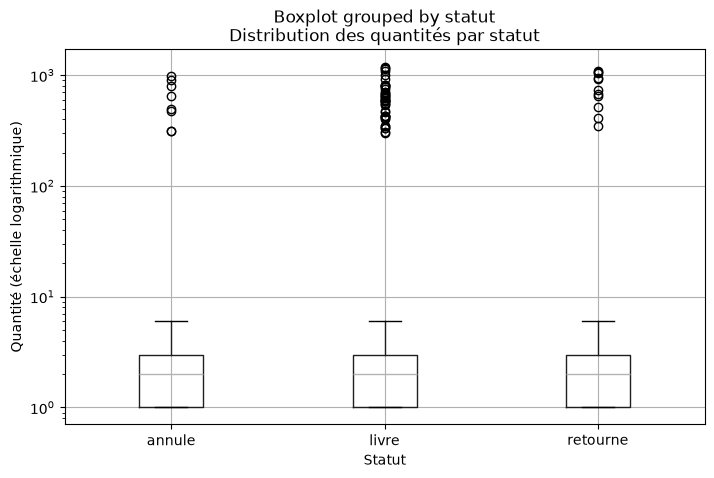

In [14]:
# Q4. Visualiser. Un boxplot par statut pour la quantité, en échelle logarithmique
#     sur l'axe des ordonnées (sans quoi les valeurs extrêmes écrasent tout le reste).

import matplotlib.pyplot as plt

# Une échelle logarithmique ne peut pas représenter les quantités nulles ou négatives.
plot_data = sales.loc[sales['quantite'] > 0, ['statut', 'quantite']]
ax = plot_data.boxplot(column='quantite', by='statut', figsize=(8, 5))
ax.set_yscale('log')
ax.set_title('Distribution des quantités par statut')
ax.set_xlabel('Statut')
ax.set_ylabel('Quantité (échelle logarithmique)')
plt.show()

In [15]:
# Q5. Appliquer un traitement différencié et JOURNALISER ce qui est fait :
#       - quantités négatives : à décider et justifier ;
#       - quantités au-delà de la borne haute IQR : à décider et justifier.
#     La fonction renvoie (df_traité, log) où log est un dict des comptes.

# Les quantités négatives sont impossibles : on retire ces lignes.
# Les valeurs au-dessus de l'IQR sont seulement atypiques : on les conserve et on les signale.
def handle_quantity_outliers(df):
    df = df.copy()
    log = {}

    negative_mask = df['quantite'] < 0
    log['quantites_negatives_supprimees'] = int(negative_mask.sum())
    df = df.loc[~negative_mask].copy()
    
    valid_quantities = df['quantite'].dropna()
    if valid_quantities.empty:
        upper_bound = float('nan')
        high_outlier_mask = pd.Series(False, index=df.index)
    else:
        _, upper_bound = iqr_bounds(valid_quantities)
        high_outlier_mask = df['quantite'] > upper_bound

    log['borne_haute_iqr'] = float(upper_bound)
    log['valeurs_au_dessus_iqr_conservees'] = int(high_outlier_mask.sum())
    log['lignes_finales'] = len(df)

    return df, log


sales_fixed, quantity_log = handle_quantity_outliers(sales)
print(quantity_log)

{'quantites_negatives_supprimees': 30, 'borne_haute_iqr': 6.0, 'valeurs_au_dessus_iqr_conservees': 61, 'lignes_finales': 17579}


---
## Atelier 3.3 — Doublons et incohérences textuelles (45 min)

### Partie guidée

In [16]:
print('Doublons stricts (toutes colonnes identiques) :', sales.duplicated().sum())
print('Doublons sur id_commande seul                 :', sales.duplicated('id_commande').sum())

Doublons stricts (toutes colonnes identiques) : 240
Doublons sur id_commande seul                 : 240


Les deux comptes diffèrent : certaines lignes partagent un identifiant de commande sans
être identiques. Avant de supprimer, il faut regarder ce qui les distingue.

In [17]:
repeated_ids = sales[sales.duplicated('id_commande', keep=False)]['id_commande'].unique()[:2]
sales[sales['id_commande'].isin(repeated_ids)].sort_values('id_commande')

,id_commande,date_commande,id_client,id_produit,id_magasin,quantite,prix_unitaire,remise_pct,canal,statut,ville_livraison
13,CMD0000105,2023/07/29 19:47,C01517,P0014,M99,2,1053.99,NaN,web,livre,Lyon
13443,CMD0000105,2023/07/29 19:47,C01517,P0014,M99,2,1053.99,NaN,web,livre,Lyon
18,CMD0000173,24-05-2023,C02747,P0002,M02,2,538.60,15.0,BOUTIQUE,annule,Marseille
2557,CMD0000173,24-05-2023,C02747,P0002,M02,2,538.60,15.0,BOUTIQUE,annule,Marseille


In [18]:
# Faux doublons textuels : la même ville écrite de plusieurs façons
print(sales['ville_livraison'].value_counts().head(12))

ville_livraison
Toulouse      1560
Lyon          1523
Paris         1521
Bordeaux      1510
Lille         1475
Marseille     1473
Nantes        1471
Strasbourg    1379
STRASBOURG     295
lyon           278
LYON           275
paris          275
Name: count, dtype: int64


In [19]:
def normalize_text(series):
    """Casse, espaces et accents : trois sources de faux niveaux."""
    text = series.astype(str).str.strip().str.lower()
    text = text.str.normalize('NFKD').str.encode('ascii', 'ignore').str.decode('utf-8')
    return text.str.replace(r'\s+', ' ', regex=True)


print('Modalités avant normalisation :', sales['ville_livraison'].nunique())
print('Modalités après normalisation :', normalize_text(sales['ville_livraison']).nunique())

Modalités avant normalisation : 33
Modalités après normalisation : 9


### Le piège : ne jamais normaliser les colonnes identifiantes

La tentation est grande d'écrire `for column in df.select_dtypes('object'): df[column] = normalize_text(df[column])`
et d'en finir. **C'est une erreur qui casse silencieusement tout le pipeline.** Les colonnes
`id_client`, `id_produit`, `id_magasin` sont du texte pour pandas, mais ce sont des **clés**.
Les passer en minuscules transforme `P0027` en `p0027`, et la jointure de la séance 6 ne
trouvera plus aucune correspondance : vous obtiendrez un jeu entièrement vide, sans la
moindre erreur levée.

Déclarez donc explicitement les colonnes à normaliser, plutôt que de les déduire du type.

In [20]:
TEXT_COLUMNS = ['canal', 'statut', 'ville_livraison']          # descriptives uniquement
KEY_COLUMNS = ['id_commande', 'id_client', 'id_produit', 'id_magasin']  # à préserver

trial = sales.copy()
for column in TEXT_COLUMNS:
    trial[column] = normalize_text(trial[column])

print('Clés intactes            :', trial['id_produit'].str.isupper().all())
print('Descriptives normalisées :', trial['canal'].nunique(), 'modalités')

Clés intactes            : True
Descriptives normalisées : 3 modalités


### Partie autonome

In [26]:
# Q6. Normaliser toutes les colonnes de TEXT_COLUMNS, puis recompter les doublons stricts.
#     Le compte augmente-t-il ? Expliquez pourquoi dans un commentaire.

TEXT_COLUMNS = ["canal", "statut", "ville_livraison"]

sales_normalized = sales.copy()

duplicates_before = int(sales_normalized.duplicated().sum())

for column in TEXT_COLUMNS:
    sales_normalized[column] = normalize_text(
        sales_normalized[column]
    )

duplicates_after = int(sales_normalized.duplicated().sum())

print("Avant :", duplicates_before)
print("Après :", duplicates_after)

# Le nombre de doublons stricts ne change pas après normalisation.
# Les différences de casse, d'espaces ou d'accents ne suffisaient
# pas à expliquer les différences entre les lignes :
# au moins une autre colonne reste différente.



Avant : 240
Après : 240


In [58]:
# Q7. Dans customers, identifier les doublons MÉTIER : même ville, même segment,
#     même date d'inscription et même âge, mais identifiant différent.
#     Combien de couples trouvez-vous ? Que proposez-vous d'en faire ?


customers_cp = customers.copy()

for column in ["ville", "segment"]:
    customers_cp[column] = normalize_text(
        customers_cp[column]
    )

TEXT_COLUMNS = [
    "ville",
    "segment",
    "date_inscription",
    "age",
]

unique_customers = customers_cp.drop_duplicates(
    subset=TEXT_COLUMNS + ["id_client"]
)

suspect_mask = unique_customers.duplicated(
    subset=TEXT_COLUMNS,
    keep=False,
)

suspect_customers = unique_customers.loc[suspect_mask]

counts = suspect_customers[TEXT_COLUMNS].value_counts(
    dropna=False
)

pairs_per_combination = counts * (counts - 1) // 2

number_of_pairs = pairs_per_combination.sum()

print("Clients par combinaison :")
print(counts)

print("Couples par combinaison :")
print(pairs_per_combination)

print("Total des couples :", number_of_pairs)



# Couples suspect : 60
# Proposition : On conserve ces clients en attendant une vérification.
# Des personnes différentes peuvent partager ces caractéristiques.
# Il faudrait d'autres information  pour confirmer qu'il s'agit réellement de doublons.




Clients par combinaison :
ville       segment        date_inscription  age 
lyon        particulier    2019-11-29        39.0    2
                           2020-07-15        35.0    2
marseille   professionnel  2022-04-08        26.0    2
bordeaux    particulier    2019-11-28        23.0    2
toulouse    particulier    2019-02-13        41.0    2
paris       particulier    2023-04-30        27.0    2
lyon        professionnel  2019-10-28        44.0    2
bordeaux    professionnel  2023-01-10        46.0    2
nantes      particulier    2020-05-25        56.0    2
bordeaux    professionnel  2021-03-11        33.0    2
strasbourg  professionnel  2020-04-11        23.0    2
nantes      professionnel  2021-07-12        59.0    2
toulouse    particulier    2021-04-03        41.0    2
paris       professionnel  2019-06-29        29.0    2
lille       particulier    2021-10-22        45.0    2
strasbourg  professionnel  2020-12-12        56.0    2
lille       particulier    2022-01-25       

---
## Atelier 3.4 — Un module de nettoyage idempotent (50 min)

**Idempotent** signifie que réappliquer la fonction à son propre résultat ne change plus rien.
C'est une propriété essentielle : un pipeline relancé deux fois par erreur ne doit pas
produire un jeu de données différent.

In [65]:
def clean_sales(df, drop_negative_quantities=True, max_quantity=None, verbose=True):
    """Nettoie les ventes et renvoie le DataFrame nettoyé et son journal."""
    df = df.copy()
    log = {'lignes_initiales': len(df)}

    # 1. Convertir les prix avec la fonction déjà définie au début.
    log['prix_manquants_avant'] = int(df['prix_unitaire'].isna().sum())
    df['prix_unitaire'] = parse_price(df['prix_unitaire'])
    log['prix_manquants_apres'] = int(df['prix_unitaire'].isna().sum())

    # 2. Normaliser uniquement les colonnes descriptives.
    for column in ['canal', 'statut', 'ville_livraison']:
        normalized = normalize_text(df[column])
        log[column + '_modifications'] = int((df[column] != normalized).sum())
        df[column] = normalized

    # 3. Supprimer les doublons stricts.
    log['doublons_supprimes'] = int(df.duplicated().sum())
    df = df.drop_duplicates().copy()

    # 4. Convertir les cinq formats de date présents dans le fichier.
    original_dates = df['date_commande'].copy()
    df['date_commande'] = pd.to_datetime(
        original_dates, format='%Y-%m-%d', errors='coerce'
    )
    for date_format in ['%d/%m/%Y', '%d-%m-%Y', '%Y/%m/%d %H:%M', '%d %b %Y']:
        parsed_dates = pd.to_datetime(
            original_dates, format=date_format, errors='coerce'
        )
        df['date_commande'] = df['date_commande'].fillna(parsed_dates)

    missing_date = df['date_commande'].isna()
    log['lignes_sans_date_supprimees'] = int(missing_date.sum())
    df = df.loc[~missing_date].copy()

    # 5. Une remise absente est supposée correspondre à aucune remise.
    log['remises_remplacees_par_zero'] = int(df['remise_pct'].isna().sum())
    df['remise_pct'] = df['remise_pct'].fillna(0)

    # 6. Supprimer les quantités négatives si demandé.
    log['quantites_negatives_supprimees'] = 0
    if drop_negative_quantities:
        negative = df['quantite'] < 0
        log['quantites_negatives_supprimees'] = int(negative.sum())
        df = df.loc[~negative].copy()

    # 7. Appliquer un plafond fixe uniquement s'il est renseigné.
    log['quantites_plafonnees'] = 0
    if max_quantity is not None:
        too_high = df['quantite'] > max_quantity
        log['quantites_plafonnees'] = int(too_high.sum())
        df.loc[too_high, 'quantite'] = max_quantity

    # 8. Calculer le montant après remise.
    df['montant'] = (
        df['quantite'] * df['prix_unitaire']
        * (1 - df['remise_pct'] / 100)
    )
    log['montants_calcules'] = int(df['montant'].notna().sum())

    # Les transformations peuvent rendre de nouvelles lignes identiques.
    log['doublons_apres_nettoyage'] = int(df.duplicated().sum())
    df = df.drop_duplicates().copy()
    log['lignes_finales'] = len(df)

    if verbose:
        for key, value in log.items():
            print(f'  {key:<36} {value}')

    return df, log


clean_sales_df, cleaning_log = clean_sales(
    pd.read_csv(RAW_DIR / 'ventes_brutes.csv')
)


  lignes_initiales                     17609
  prix_manquants_avant                 0
  prix_manquants_apres                 0
  canal_modifications                  3560
  statut_modifications                 0
  ville_livraison_modifications        15544
  doublons_supprimes                   240
  lignes_sans_date_supprimees          347
  remises_remplacees_par_zero          1874
  quantites_negatives_supprimees       30
  quantites_plafonnees                 0
  montants_calcules                    16992
  doublons_apres_nettoyage             0
  lignes_finales                       16992


In [66]:
# Q8. Vérifier l'idempotence : un second passage ne doit rien changer.

second_pass, _ = clean_sales(clean_sales_df, verbose=False)

assert len(second_pass) == len(clean_sales_df), "la fonction n'est pas idempotente"
assert second_pass.equals(clean_sales_df), 'le second passage modifie encore des valeurs'
print('OK — fonction idempotente')

OK — fonction idempotente


In [67]:
# Export du résultat et du journal, pour la séance 4.

import json

save_dataset(clean_sales_df, 'ventes_nettoyees')

with open(PROCESSED_DIR / 'journal_nettoyage.json', 'w', encoding='utf-8') as file:
    json.dump(cleaning_log, file, indent=2, ensure_ascii=False, default=str)

kept_ratio = len(clean_sales_df) / cleaning_log['lignes_initiales']
print('Lignes conservées :', len(clean_sales_df), f'({kept_ratio:.1%} du brut)')

écrit : ventes_nettoyees.parquet (16992, 12)
Lignes conservées : 16992 (96.5% du brut)


---
## Livrable de la séance

- `src/cleaning.py` contenant `clean_sales`, importable et testée ;
- `data/processed/ventes_nettoyees.parquet` ;
- `data/processed/journal_nettoyage.json` ;
- le tableau des stratégies (question 2) avec sa justification écrite, colonne par colonne.

**Ce tableau sera repris tel quel dans votre note méthodologique de projet et vous sera
demandé en soutenance.** Attendez-vous à la question : *pourquoi la médiane plutôt que la
moyenne sur cette colonne ?*

